In [16]:
import import_ipynb
import data_analysis_regression

Top Features สำหรับทำนาย Credit_Limit:
                  feature      f_score       f_pvalue  mutual_info  rfe_rank
15  Avg_Utilization_Ratio  2432.601629   0.000000e+00     0.762319         1
5         Income_Category  3818.741260   0.000000e+00     0.213272         1
2                  Gender  1793.463987   0.000000e+00     0.129553         1
10    Total_Revolving_Bal    22.299996   2.371283e-06     0.126860         1
16     Card_Category_Blue  2860.832605   0.000000e+00     0.116680         1
12        Total_Trans_Amt   242.378319   7.156694e-54     0.107190         1
19   Card_Category_Silver  1863.773769   0.000000e+00     0.084496         1
13         Total_Trans_Ct    46.951240   7.810232e-12     0.039095         5
17     Card_Category_Gold   519.128770  1.972602e-111     0.035925         1
3         Dependent_count    40.271042   2.329421e-10     0.015016         2


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [ ]:
reg_features = ['Income_Category', 'Card_Category_Blue', 'Total_Trans_Amt',
                'Card_Category_Silver', 'Total_Trans_Ct', 'Card_Category_Gold',
                'Dependent_count']

Xr_train = data_analysis_regression.Xr_train[reg_features]
Xr_test  = data_analysis_regression.Xr_test[reg_features]
yr_train = data_analysis_regression.yr_train
yr_test  = data_analysis_regression.yr_test

continuous_cols = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Dependent_count']
scaler = StandardScaler()
Xr_train_scaled = Xr_train.copy()
Xr_test_scaled  = Xr_test.copy()
Xr_train_scaled[continuous_cols] = scaler.fit_transform(Xr_train[continuous_cols])  
Xr_test_scaled[continuous_cols]  = scaler.transform(Xr_test[continuous_cols])

X_train = Xr_train_scaled.values.astype(float)
X_test  = Xr_test_scaled.values.astype(float)
y_train = np.asarray(yr_train, dtype=float).ravel()
y_test  = np.asarray(yr_test,  dtype=float).ravel()
poly_idx = [reg_features.index(c) for c in continuous_cols]    

print(X_train.shape, X_test.shape, "| target mean/std (train):", y_train.mean().round(1), y_train.std().round(1))

(8101, 7) (2026, 7) | target mean/std (train): 8636.5 9085.9


In [4]:
rows = []

def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    row = {"model": name, "R2": r2_score(y_true, y_pred), "MSE": mse,
           "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_true, y_pred)}
    rows[:] = [r for r in rows if r["model"] != name]     # รันซ้ำแล้วแทนที่ ไม่ต่อท้าย
    rows.append(row)
    return row

evaluate("baseline (train mean)", y_test, np.full_like(y_test, y_train.mean()))

{'model': 'baseline (train mean)',
 'R2': -6.3712771074531105e-06,
 'MSE': 82777244.46388419,
 'RMSE': 9098.200067259688,
 'MAE': 6818.055653982488}

In [5]:
import os, pickle
os.makedirs("models", exist_ok=True)

def save_model(model, path):
    """บันทึกโมเดลที่ fit แล้ว ทั้ง hyperparameter และ parameter ที่เรียนได้ ลงไฟล์"""
    with open(path, "wb") as f:
        pickle.dump(model, f)

def load_model(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def check_save_load(model, path, X_test, name):
    """save -> load -> predict บนข้อมูล test แล้วเทียบกับโมเดลต้นฉบับ  max_abs_diff ควรเป็น 0"""
    save_model(model, path)
    reloaded = load_model(path)
    diff = float(np.max(np.abs(np.asarray(model.predict(X_test)) - np.asarray(reloaded.predict(X_test)))))
    return {"model": name, "file": path, "size_kb": round(os.path.getsize(path) / 1024, 1), "max_abs_diff": diff}

In [6]:
class LinearRegressionScratch:
    def __init__(self):
        self.coef_ = None
        self.intercept_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        X_b = np.c_[np.ones(len(X)), X]
        A, b = X_b.T @ X_b, X_b.T @ y
        try:
            theta = np.linalg.solve(A, b)
        except np.linalg.LinAlgError:          # singular (e.g. perfectly collinear columns)
            theta = np.linalg.pinv(A) @ b
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

In [7]:
class GradientDescentRegression:
    """Linear regression trained with batch gradient descent on MSE. Inputs are standardized internally
    (mean 0, std 1 per column) so rare dummy columns and power terms converge at the same speed; the learned
    coefficients are converted back to the original feature units."""

    def __init__(self, iterations=3000, learning_rate=0.1):
        self.iterations = iterations
        self.learning_rate = learning_rate
        self.coef_ = None
        self.intercept_ = 0.0
        self.losses = []

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        m = len(y)
        mu, sd = X.mean(axis=0), X.std(axis=0)
        sd[sd == 0] = 1.0
        Z = (X - mu) / sd
        w, b = np.zeros(Z.shape[1]), float(y.mean())
        self.losses = []
        for _ in range(self.iterations):
            error = Z @ w + b - y
            self.losses.append(np.mean(error ** 2))
            b -= self.learning_rate * error.mean()
            w -= self.learning_rate * (Z.T @ error) / m
        self.coef_ = w / sd                      # back to original units
        self.intercept_ = b - np.sum(w * mu / sd)
        return self

In [8]:
class PolyRegressionScratch:
    
    def __init__(self, degree=2, poly_idx=None, solver="normal", iterations=5000, learning_rate=0.05):
        self.degree, self.poly_idx, self.solver = degree, poly_idx, solver
        self.iterations, self.learning_rate = iterations, learning_rate

    def _expand(self, X):
        X = np.asarray(X, dtype=float)
        idx = self.poly_idx if self.poly_idx is not None else list(range(X.shape[1]))
        return np.column_stack([X] + [X[:, idx] ** p for p in range(2, self.degree + 1)])

    def fit(self, X, y):
        Z = self._expand(X)
        if self.solver == "gd":
            self.model = GradientDescentRegression(self.iterations, self.learning_rate)
        else:
            self.model = LinearRegressionScratch()
        self.model.fit(Z, y)
        return self

    def predict(self, X):
        return self.model.predict(self._expand(X))

In [9]:
class MultipleRegressionScratch:
    """Multiple linear regression (OLS) via the normal equation, with classical inference:
    standard errors, t-statistics, p-values, R2 / adjusted R2, overall F-test and VIF.
    Predictions equal LinearRegressionScratch; the extra value is telling which features matter."""

    def __init__(self):
        self.coef_ = None
        self.intercept_ = None

    def fit(self, X, y, feature_names=None):
        from scipy import stats
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        n, k = X.shape
        p = k + 1                                           # parameters incl. intercept
        X_b = np.c_[np.ones(n), X]
        XtX_inv = np.linalg.pinv(X_b.T @ X_b)               # pinv also copes with collinear columns
        theta = XtX_inv @ X_b.T @ y
        resid = y - X_b @ theta

        sse = float(resid @ resid)
        sst = float(((y - y.mean()) ** 2).sum())
        self.df_resid_ = n - p
        self.sigma2_ = sse / self.df_resid_                 # unbiased estimate of the error variance
        self.se_ = np.sqrt(np.diag(XtX_inv) * self.sigma2_)
        self.t_ = theta / self.se_
        self.p_ = 2 * stats.t.sf(np.abs(self.t_), self.df_resid_)

        self.r2_ = 1 - sse / sst
        self.adj_r2_ = 1 - (1 - self.r2_) * (n - 1) / (n - p)
        self.f_ = ((sst - sse) / k) / self.sigma2_
        self.f_p_ = float(stats.f.sf(self.f_, k, self.df_resid_))

        # VIF_j = 1 / (1 - R2_j) = j-th diagonal entry of the inverse correlation matrix
        corr = np.corrcoef(X, rowvar=False)
        self.vif_ = np.diag(np.linalg.pinv(np.atleast_2d(corr)))

        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]
        self.feature_names_ = list(feature_names) if feature_names is not None else [f"x{i}" for i in range(k)]
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

    def summary(self):
        names = ["(intercept)"] + self.feature_names_
        coef = np.r_[self.intercept_, self.coef_]
        return pd.DataFrame({"coef": coef, "std_err": self.se_, "t": self.t_, "p_value": self.p_,
                             "VIF": np.r_[np.nan, self.vif_]}, index=names)

In [10]:
lin = LinearRegressionScratch().fit(X_train, y_train)
evaluate("Linear scratch (normal equation)", y_test, lin.predict(X_test))
pd.Series(lin.coef_, index=reg_features).round(2)



Income_Category          3692.08
Card_Category_Blue     -20319.75
Total_Trans_Amt          1055.12
Card_Category_Silver    -4545.19
Total_Trans_Ct           -453.52
Card_Category_Gold      -1823.32
Dependent_count           221.17
dtype: float64

max |coef difference| vs normal equation: 148.6887


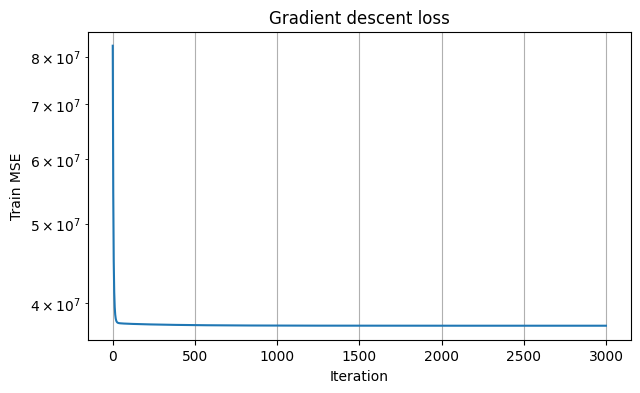

[{'model': 'Polynomial scratch (degree 2)',
  'R2': 0.5386929202385272,
  'MSE': 38185485.62402556,
  'RMSE': 6179.440559146561,
  'MAE': 4249.014840198183},
 {'model': 'Polynomial scratch (degree 3)',
  'R2': 0.5385141521689996,
  'MSE': 38200283.45793809,
  'RMSE': 6180.63778731112,
  'MAE': 4256.479575563595},
 {'model': 'Polynomial scratch (degree 2, gradient descent)',
  'R2': 0.5387158201918312,
  'MSE': 38183590.041069984,
  'RMSE': 6179.287179041769,
  'MAE': 4248.59679392852}]

In [11]:
gd = GradientDescentRegression(iterations=3000, learning_rate=0.1).fit(X_train, y_train)
evaluate("Linear scratch (gradient descent)", y_test, gd.predict(X_test))

print("max |coef difference| vs normal equation:", np.abs(gd.coef_ - lin.coef_).max().round(4))
plt.figure(figsize=(7, 4)); plt.plot(gd.losses); plt.yscale("log")
plt.xlabel("Iteration"); plt.ylabel("Train MSE"); plt.title("Gradient descent loss"); plt.grid(True); plt.show()
for degree in (2, 3):
    poly = PolyRegressionScratch(degree=degree, poly_idx=poly_idx, solver="normal").fit(X_train, y_train)
    evaluate(f"Polynomial scratch (degree {degree})", y_test, poly.predict(X_test))

# Same degree-2 model trained by gradient descent: should match the normal-equation version
poly_gd = PolyRegressionScratch(degree=2, poly_idx=poly_idx, solver="gd").fit(X_train, y_train)
evaluate("Polynomial scratch (degree 2, gradient descent)", y_test, poly_gd.predict(X_test))
rows[-3:]

In [12]:
mr = MultipleRegressionScratch().fit(X_train, y_train, feature_names=reg_features)
evaluate("Multiple regression (OLS, scratch)", y_test, mr.predict(X_test))

print("max |coef difference| vs normal equation:", np.abs(mr.coef_ - lin.coef_).max().round(6))
print(f"train R2 = {mr.r2_:.4f} | adjusted R2 = {mr.adj_r2_:.4f} | F = {mr.f_:.1f} (p = {mr.f_p_:.3g}) | df_resid = {mr.df_resid_}")
mr.summary().round(4)

max |coef difference| vs normal equation: 0.0
train R2 = 0.5452 | adjusted R2 = 0.5448 | F = 1385.7 (p = 0) | df_resid = 8093


,coef,std_err,t,p_value,VIF
(intercept),23003.9971,1586.8709,14.4965,0.0000,NaN
Income_Category,3692.0776,53.6591,68.8061,0.0000,1.0244
Card_Category_Blue,-20319.7526,1587.1470,-12.8027,0.0000,34.0111
Total_Trans_Amt,1055.1172,117.3571,8.9907,0.0000,2.9685
Card_Category_Silver,-4545.1862,1610.5722,-2.8221,0.0048,28.4706
Total_Trans_Ct,-453.5192,116.4735,-3.8938,0.0001,2.9239
Card_Category_Gold,-1823.3182,1706.4384,-1.0685,0.2853,7.1224
Dependent_count,221.1704,68.3855,3.2342,0.0012,1.0080


In [13]:
# นิยาม class ของ 3 โมเดลที่ save ไว้จาก notebook อื่น pickle ต้องเจอ class ชื่อเดียวกันตอน load
class BayesianLinearRegression:
    def __init__(self, alpha=1.0, beta=None, evidence=True, max_iter=300, tol=1e-6):
        self.alpha = alpha
        self.beta = beta
        self.evidence = evidence
        self.max_iter = max_iter
        self.tol = tol
        self.mu_post = None
        self.Sigma_post = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        n, d = X.shape
        self.x_mean_ = X.mean(axis=0)
        self.y_mean_ = y.mean()
        Xc = X - self.x_mean_
        yc = y - self.y_mean_
        if self.beta is None:
            self.beta = 1.0 / np.var(yc)
        XtX = Xc.T @ Xc
        Xty = Xc.T @ yc
        eig = np.linalg.eigvalsh(XtX)
        for _ in range(self.max_iter if self.evidence else 1):
            Sigma = np.linalg.inv(self.beta * XtX + self.alpha * np.eye(d))
            m = self.beta * Sigma @ Xty
            if not self.evidence:
                break
            lam = self.beta * eig
            gamma = np.sum(lam / (self.alpha + lam))
            alpha_new = gamma / max(m @ m, 1e-12)
            rss = np.sum((yc - Xc @ m) ** 2)
            beta_new = (n - gamma) / max(rss, 1e-12)
            converged = (abs(alpha_new - self.alpha) < self.tol * self.alpha and
                         abs(beta_new - self.beta) < self.tol * self.beta)
            self.alpha, self.beta = alpha_new, beta_new
            if converged:
                break
        self.Sigma_post = np.linalg.inv(self.beta * XtX + self.alpha * np.eye(d))
        self.w_ = self.beta * self.Sigma_post @ Xty
        self.intercept_ = self.y_mean_ - self.x_mean_ @ self.w_
        self.mu_post = np.r_[self.intercept_, self.w_].reshape(-1, 1)
        return self

    def predict(self, X, return_std=False):
        X = np.asarray(X, dtype=float)
        y_mean = X @ self.w_ + self.intercept_
        if return_std:
            Xc = X - self.x_mean_
            var = np.sum(Xc @ self.Sigma_post * Xc, axis=1) + 1.0 / self.beta
            return y_mean, np.sqrt(var)
        return y_mean


class HuberRegressionScratch:
    def __init__(self, delta=1500.0, max_iter=50, tol=1e-6, init="ols"):
        self.delta = delta
        self.max_iter = max_iter
        self.tol = tol
        self.init = init
        self.coef_ = None
        self.intercept_ = None
        self.loss_history = []

    def _huber_loss(self, residual):
        abs_r = np.abs(residual)
        quad = 0.5 * residual ** 2
        lin = self.delta * (abs_r - 0.5 * self.delta)
        return np.mean(np.where(abs_r <= self.delta, quad, lin))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        m, n = X.shape
        X_b = np.c_[np.ones((m, 1)), X]
        y = np.asarray(y, dtype=float).ravel()
        self.loss_history = []
        if self.init == "zeros":
            theta = np.zeros(n + 1)
        else:
            theta = np.linalg.lstsq(X_b, y, rcond=None)[0]
        for i in range(self.max_iter):
            residual = X_b @ theta - y
            abs_r = np.abs(residual)
            weights = np.where(abs_r <= self.delta, 1.0, self.delta / (abs_r + 1e-8))
            WX = X_b * weights[:, None]
            theta_new = np.linalg.solve(X_b.T @ WX, WX.T @ y)
            self.loss_history.append(self._huber_loss(residual))
            if np.linalg.norm(theta_new - theta) < self.tol:
                theta = theta_new
                break
            theta = theta_new
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_


class MARS:
    def __init__(self, max_terms=25, n_knots=20, gcv_penalty=3, max_degree=1):
        self.max_terms = max_terms
        self.n_knots = n_knots
        self.gcv_penalty = gcv_penalty
        self.max_degree = max_degree
        self.basis_functions = []
        self.fixed_linear_features = []
        self.coef_ = None

    @staticmethod
    def _hinge(x, knot, sign):
        if sign == 1:
            return np.maximum(0, x - knot)
        return np.maximum(0, knot - x)

    def _term_column(self, X, term):
        col = np.ones(X.shape[0])
        for (f_idx, knot, sign) in term:
            col = col * self._hinge(X[:, f_idx], knot, sign)
        return col

    def _build_design_matrix(self, X, basis_functions):
        n = X.shape[0]
        B = np.ones((n, 1))
        for f_idx in self.fixed_linear_features:
            B = np.hstack([B, X[:, f_idx].reshape(-1, 1)])
        for term in basis_functions:
            col = self._term_column(X, term).reshape(-1, 1)
            B = np.hstack([B, col])
        return B

    def _fit_linear(self, B, y):
        coef, *_ = np.linalg.lstsq(B, y, rcond=None)
        return coef

    def _rss(self, B, y, coef):
        return np.sum((y - B @ coef) ** 2)

    def _gcv(self, B, y, coef):
        n = len(y)
        rss = self._rss(B, y, coef)
        terms = B.shape[1]
        effective_params = terms + self.gcv_penalty * (terms - 1) / 2
        denom = (1 - effective_params / n) ** 2
        return (rss / n) / denom if denom > 0 else np.inf

    def fit(self, X, y, spline_features, fixed_linear_features):
        X = np.asarray(X)
        y = np.asarray(y).ravel()
        self.fixed_linear_features = fixed_linear_features
        self.basis_functions = []
        improved = True
        while improved and len(self.basis_functions) < self.max_terms:
            B_current = self._build_design_matrix(X, self.basis_functions)
            current_rss = self._rss(B_current, y, self._fit_linear(B_current, y))
            best_rss, best_candidate = None, None
            parents = [()] + [t for t in self.basis_functions if len(t) < self.max_degree]
            for parent in parents:
                used_features = {f for (f, k, s) in parent}
                for f_idx in spline_features:
                    if f_idx in used_features:
                        continue
                    knots = np.percentile(X[:, f_idx], np.linspace(2, 98, self.n_knots))
                    for knot in knots:
                        term_pos = parent + ((f_idx, knot, 1),)
                        term_neg = parent + ((f_idx, knot, -1),)
                        trial = self.basis_functions + [term_pos, term_neg]
                        B_trial = self._build_design_matrix(X, trial)
                        coef_trial = self._fit_linear(B_trial, y)
                        rss_trial = self._rss(B_trial, y, coef_trial)
                        if best_rss is None or rss_trial < best_rss:
                            best_rss, best_candidate = rss_trial, (term_pos, term_neg)
            if best_rss is not None and best_rss < current_rss - 1e-6:
                self.basis_functions += list(best_candidate)
            else:
                improved = False
        self._prune(X, y)
        B_final = self._build_design_matrix(X, self.basis_functions)
        self.coef_ = self._fit_linear(B_final, y)
        return self

    def _prune(self, X, y):
        current = list(self.basis_functions)
        B = self._build_design_matrix(X, current)
        best_gcv = self._gcv(B, y, self._fit_linear(B, y))
        best_functions = list(current)
        while len(current) > 0:
            gcvs = []
            for i in range(len(current)):
                trial = current[:i] + current[i + 1:]
                B_trial = self._build_design_matrix(X, trial)
                gcvs.append(self._gcv(B_trial, y, self._fit_linear(B_trial, y)))
            min_idx = int(np.argmin(gcvs))
            current = current[:min_idx] + current[min_idx + 1:]
            if gcvs[min_idx] < best_gcv:
                best_gcv = gcvs[min_idx]
                best_functions = list(current)
        self.basis_functions = best_functions

    def predict(self, X):
        X = np.asarray(X)
        B = self._build_design_matrix(X, self.basis_functions)
        return B @ self.coef_

In [14]:
# โหลดโมเดลใหม่ 3 ตัวที่ save ไว้จาก notebook ของแต่ละตัว ไม่ต้อง fit ซ้ำ
novel = {
    "Bayesian Linear Regression (scratch)": load_model("models/bayesian.pkl"),
    "Huber Regression (scratch)":           load_model("models/huber.pkl"),
    "MARS (scratch)":                       load_model("models/mars.pkl"),
}
for name, mdl in novel.items():
    evaluate(name, y_test, mdl.predict(X_test))
rows[-3:]

[{'model': 'Bayesian Linear Regression (scratch)',
  'R2': 0.538567938836485,
  'MSE': 38195831.174181476,
  'RMSE': 6180.2775968544875,
  'MAE': 4250.908829121071},
 {'model': 'Huber Regression (scratch)',
  'R2': 0.538508612655074,
  'MSE': 38200742.00071501,
  'RMSE': 6180.67488230169,
  'MAE': 4252.173550182181},
 {'model': 'MARS (scratch)',
  'R2': 0.5629196264591529,
  'MSE': 36180078.41765115,
  'RMSE': 6014.987815253756,
  'MAE': 4052.1674811778653}]

,R2,MSE,RMSE,MAE
model,,,,
MARS (scratch),0.563,3.618008e+07,6014.988,4052.167
"Polynomial scratch (degree 2, gradient descent)",0.539,3.818359e+07,6179.287,4248.597
Polynomial scratch (degree 2),0.539,3.818549e+07,6179.441,4249.015
Bayesian Linear Regression (scratch),0.539,3.819583e+07,6180.278,4250.909
Linear scratch (gradient descent),0.539,3.819972e+07,6180.592,4251.971
Polynomial scratch (degree 3),0.539,3.820028e+07,6180.638,4256.480
Linear scratch (normal equation),0.539,3.820074e+07,6180.675,4252.174
Huber Regression (scratch),0.539,3.820074e+07,6180.675,4252.174
"Multiple regression (OLS, scratch)",0.539,3.820074e+07,6180.675,4252.174


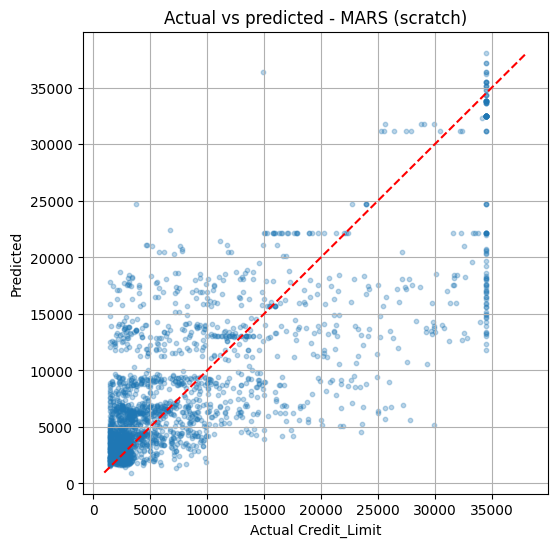

In [15]:
results = pd.DataFrame(rows).set_index("model").sort_values("R2", ascending=False)
display(results.round(3))

best_name = results.drop(index=[i for i in results.index if "baseline" in i or "sklearn" in i]).index[0]

# ใช้ lambda เพื่อคำนวณเฉพาะโมเดลที่ชนะ ไม่ fit polynomial ซ้ำโดยไม่จำเป็น
predictors = {
    "Linear scratch (normal equation)": lambda: lin.predict(X_test),
    "Linear scratch (gradient descent)": lambda: gd.predict(X_test),
    "Polynomial scratch (degree 2)": lambda: PolyRegressionScratch(2, poly_idx).fit(X_train, y_train).predict(X_test),
    "Polynomial scratch (degree 3)": lambda: PolyRegressionScratch(3, poly_idx).fit(X_train, y_train).predict(X_test),
    "Polynomial scratch (degree 2, gradient descent)": lambda: poly_gd.predict(X_test),
    "Multiple regression (OLS, scratch)": lambda: mr.predict(X_test),
}
for name, mdl in novel.items():                 # Bayesian, Huber, MARS ที่โหลดมาจากไฟล์
    predictors[name] = (lambda m=mdl: m.predict(X_test))

best_pred = predictors[best_name]()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, best_pred, alpha=0.3, s=10)
lim = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
ax.plot(lim, lim, "r--"); ax.set_xlabel("Actual Credit_Limit"); ax.set_ylabel("Predicted")
ax.set_title(f"Actual vs predicted - {best_name}"); ax.grid(True); plt.show()